In [32]:
import pandas as pd
import ast
import matplotlib.pyplot as plt

df = pd.read_csv('data_jobs.csv')

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

<Axes: xlabel='skill_count', ylabel='skill_pay'>

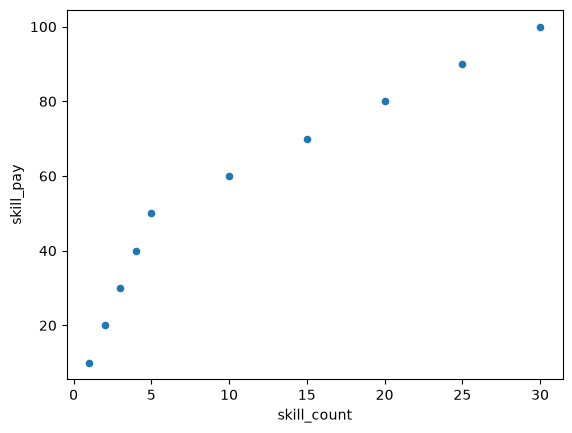

In [2]:
data = {
    'job_skills': ['python', 'sql', 'java', 'c++', 'c#', 'javascript', 'html', 'css', 'php', 'ruby'],
    'skill_count': [30, 25, 20, 15, 10, 5, 4, 3, 2, 1],
    'skill_pay': [100, 90, 80, 70, 60, 50, 40, 30, 20, 10]
}

df = pd.DataFrame(data)

df.plot(kind='scatter', x='skill_count', y='skill_pay')

In [5]:
df = df[df['job_title_short'] == 'Data Analyst']

In [ ]:
df_exploded = df.explode('job_skills')

skill_stats = df_exploded.groupby('job_skills').agg(
    skill_count=('job_skills', 'count'),
    median_salary=('salary_year_avg', 'median')
)

skill_stats = skill_stats.sort_values(by='skill_count', ascending=False).head(10)
skill_stats


,count,median
,salary_year_avg,salary_year_avg
job_skills,,
airflow,72,111175.0
airtable,6,90000.0
alteryx,124,105000.0
angular,12,109101.0
angular.js,0,NaN
...,...,...
wrike,1,75000.0
wsl,0,NaN


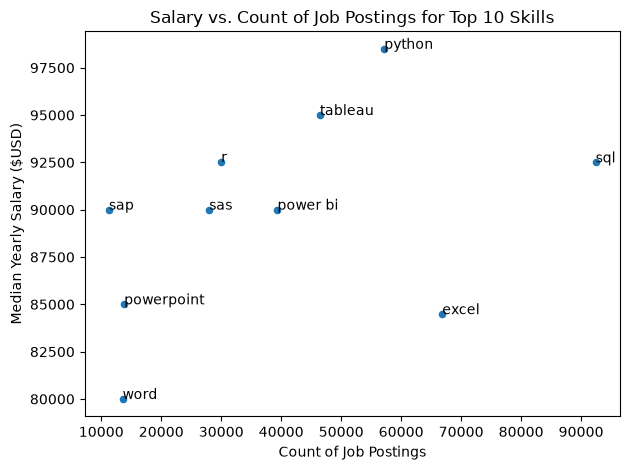

In [24]:
skill_stats.plot(kind='scatter', x='skill_count', y='median_salary')
plt.xlabel('Count of Job Postings')
plt.ylabel('Median Yearly Salary ($USD)')
plt.title('Salary vs. Count of Job Postings for Top 10 Skills')
plt.tight_layout()

for i, txt in enumerate(skill_stats.index):
    plt.text(skill_stats['skill_count'].iloc[i], skill_stats['median_salary'].iloc[i], txt)

plt.show()


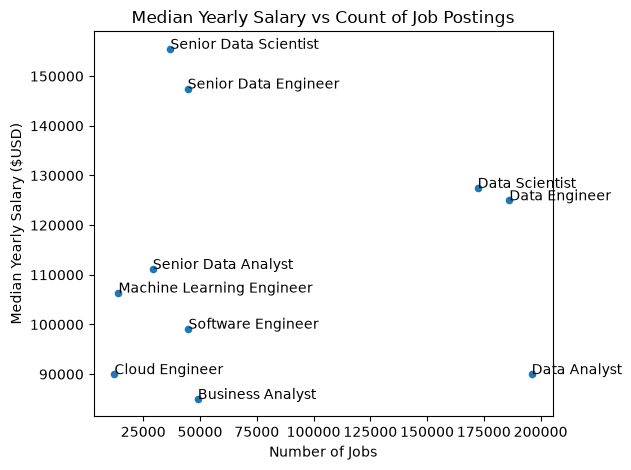

In [37]:
df_grouped = df.groupby('job_title_short').agg(
    median_yearly_salary = ('salary_year_avg', 'median'),
    number_of_jobs = ('job_title_short', 'count')
)

df_grouped.plot(kind='scatter', x='number_of_jobs', y='median_yearly_salary')

for i, txt in enumerate(df_grouped.index):
    plt.text(df_grouped['number_of_jobs'].iloc[i], df_grouped['median_yearly_salary'].iloc[i], txt)

plt.xlabel('Number of Jobs')
plt.ylabel('Median Yearly Salary ($USD)')
plt.title('Median Yearly Salary vs Count of Job Postings')
plt.tight_layout()
plt.show()

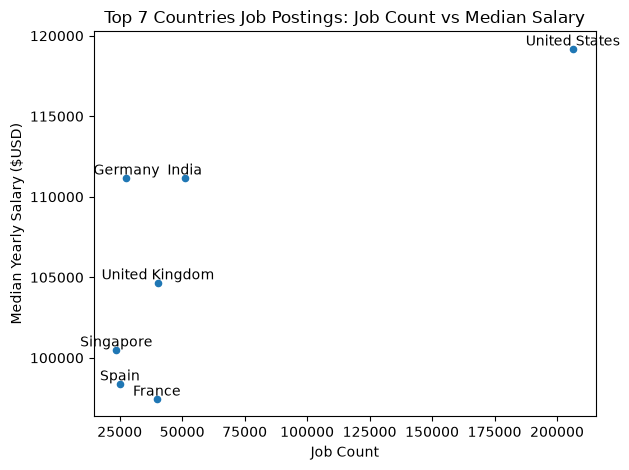

In [46]:
df_country = df.groupby('job_country').agg(
    number_of_job_postings = ('job_country', 'count'),
    median_yearly_salary = ('salary_year_avg', 'median')
)
df_country = df_country.sort_values(by='number_of_job_postings', ascending=False).head(7)
df_country.plot(kind='scatter', x='number_of_job_postings', y='median_yearly_salary')

for i, txt in enumerate(df_country.index):
    plt.text(df_country['number_of_job_postings'].iloc[i], df_country['median_yearly_salary'].iloc[i], txt, ha='center', va='bottom')

plt.xlabel('Job Count')
plt.ylabel('Median Yearly Salary ($USD)')
plt.title('Top 7 Countries Job Postings: Job Count vs Median Salary')
plt.tight_layout()
plt.show()

In [50]:
df_filtered = df[df['job_title_short'].isin(['Data Scientist', 'Data Analyst', 'Data Engineer'])]
df_filtered = df_filtered[df_filtered['job_country'] == 'United States']
df_filtered = df_filtered[df_filtered['job_schedule_type'].isin(['Full-time', 'Contractor'])]
df_filtered =df_filtered[df_filtered['salary_year_avg'].notna()]
df_filtered

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
92,Data Engineer,Remote - Data Engineer - Permanent - W2,Anywhere,via LinkedIn,Full-time,True,"Illinois, United States",2023-02-21 13:29:59,False,True,United States,year,120000.0,NaN,Apex Systems,"[sql, python]","{'programming': ['sql', 'python']}"
100,Data Scientist,"Data Scientist, Risk Data Mining - USDS","Mountain View, CA",via LinkedIn,Full-time,False,"California, United States",2023-07-31 13:01:18,False,True,United States,year,228222.0,NaN,TikTok,"[sql, r, python, express]","{'programming': ['sql', 'r', 'python'], 'webfr..."
109,Data Analyst,Senior Supply Chain Analytics Analyst,Anywhere,via Get.It,Full-time,True,"Illinois, United States",2023-10-12 13:02:19,False,True,United States,year,89000.0,NaN,Get It Recruit - Transportation,"[python, r, alteryx, tableau]","{'analyst_tools': ['alteryx', 'tableau'], 'pro..."
116,Data Scientist,Data Scientist,Anywhere,via LinkedIn,Full-time,True,"Texas, United States",2023-10-04 13:04:23,False,False,United States,year,114000.0,NaN,4 Corner Resources,"[r, python, sql, t-sql, hadoop, spark, tableau]","{'analyst_tools': ['tableau'], 'libraries': ['..."
146,Data Engineer,Data Engineer Graduate (Real Time Communicatio...,"Seattle, WA",via LinkedIn,Full-time,False,"California, United States",2023-10-21 13:06:16,False,True,United States,year,129500.0,NaN,ByteDance,"[golang, scala, python, java, hadoop, spark]","{'libraries': ['hadoop', 'spark'], 'programmin..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785563,Data Scientist,Data Scientist I/II (Model Risk Management & M...,"Pensacola, FL",via Navy Federal Credit Union - Talentify,Full-time,False,"Florida, United States",2023-01-11 06:22:10,False,False,United States,year,136400.0,NaN,Navy Federal Credit Union,"[r, python, matplotlib, ggplot2, spark, word, ...","{'analyst_tools': ['word', 'power bi', 'tablea..."
785624,Data Engineer,Data Analytics Engineer (Hybrid),"Mt Prospect, IL",via Ai-Jobs.net,Full-time,False,"Illinois, United States",2023-08-31 06:02:16,False,True,United States,year,139216.0,NaN,Bosch Group,"[go, python, r, sql, oracle, windows, alteryx,...","{'analyst_tools': ['alteryx', 'power bi', 'tab..."
785641,Data Engineer,Data Engineer,"New York, NY",via Dice,Full-time,False,Georgia,2023-01-04 16:36:07,True,False,United States,year,150000.0,NaN,"Engage Partners, Inc.",NaN,NaN
785648,Data Scientist,Director Data Scientist - Commercial Platforms...,"Pleasant Hill, CA",via Ai-Jobs.net,Full-time,False,"California, United States",2023-04-12 06:02:51,False,True,United States,year,221875.0,NaN,84.51°,"[python, azure, snowflake, spark]","{'cloud': ['azure', 'snowflake'], 'libraries':..."


C:\Users\Youssef.Louca\AppData\Local\Temp\ipykernel_22516\1680264287.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


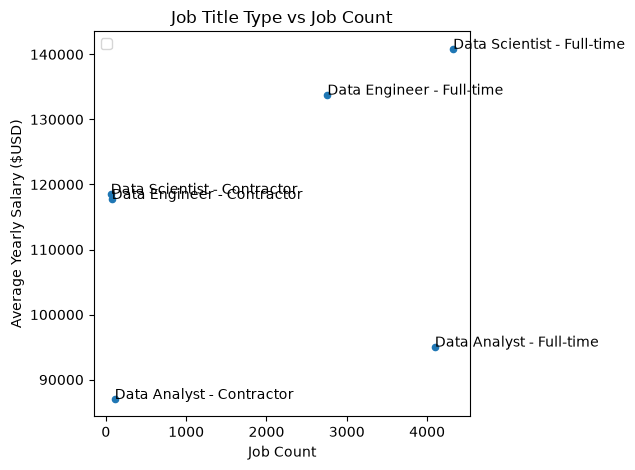

In [ ]:
df_filtered['job_title_type'] = df['job_title_short'] + ' - ' + df['job_schedule_type']

df_grouped = df_filtered.groupby('job_title_type').agg(
    average_yearly_salary = ('salary_year_avg', 'mean'),
    job_count = ('job_title_type', 'count')
)
df_grouped.plot(kind='scatter', x='job_count', y='average_yearly_salary')

# for i, txt in enumerate(df_grouped.index):
#     plt.text(df_grouped['job_count'].iloc[i], df_grouped['average_yearly_salary'].iloc[i], txt)

plt.xlabel('Job Count')
plt.ylabel('Average Yearly Salary ($USD)')
plt.title('Job Title Type vs Job Count')
plt.legend()
plt.tight_layout()
plt.show()